# **Previsão da Resistência do Concreto**

In [ ]:
from IPython.display import Image, display

url = "https://i.postimg.cc/nzYgGKgB/images.jpg"
display(Image(url=url))

# **Entendimento do Negócio**

 O processo envolve a fabricação e controle de qualidade do concreto na engenharia civil, onde é necessário determinar a resistência à compressão (em MPa) de diferentes misturas de dosagem e idades de cura para garantir a segurança estrutural.



---


# **Problema**

 A forma tradicional exige esperar 28 dias de cura para que uma prensa meça a resistência, o que gera riscos de prejuízos milionários caso a estrutura falhe, além do desperdício de cimento e tempo de laboratório em ajustes por tentativa e erro.



---


# **Solução**

Um modelo de aprendizado de máquina (Regressão Ridge) integrado a um aplicativo em Streamlit, que recebe os ingredientes da dosagem e a idade de cura para fornecer uma estimativa instantânea da resistência em MPa antes da fabricação física.

---

Datasets usado: **Concrete_Data.xls**

## **Importação e Leitura dos Dados**

Carregamento do ficheiro bruto

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor
import joblib
import urllib.request

sns.set_theme(style="whitegrid")

# Baixar o dataset automaticamente caso não exista no diretório
url_dataset = "https://archive.ics.uci.edu/ml/machine-learning-databases/concrete/compressive/Concrete_Data.xls"
try:
    urllib.request.urlretrieve(url_dataset, "Concrete_Data.xls")
    print("Dataset baixado com sucesso!")
except Exception as e:
    print(f"Erro ao baixar o dataset: {e}")

# Carregamento do ficheiro bruto Excel
df = pd.read_excel("Concrete_Data.xls")

Dataset baixado com sucesso!


Renomeação de colunas

In [ ]:
# Renomeação das colunas para o português
df.columns = [
    "cimento",
    "escoria",
    "cinza",
    "agua",
    "superplast",
    "agregado_graudo",
    "agregado_miudo",
    "idade",
    "resistencia"
]



---



## **Preparação e Limpeza dos Dados**

Verificação dos tipos de variáveis

In [ ]:
# Tipos de dados de cada coluna (todas devem ser numéricas)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   cimento          1030 non-null   float64
 1   escoria          1030 non-null   float64
 2   cinza            1030 non-null   float64
 3   agua             1030 non-null   float64
 4   superplast       1030 non-null   float64
 5   agregado_graudo  1030 non-null   float64
 6   agregado_miudo   1030 non-null   float64
 7   idade            1030 non-null   int64  
 8   resistencia      1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


Verificação de valores nulos

In [ ]:
# Verificação de valores nulos e resumo do DataFrame
print(df.isnull().sum())
display(df.head())

cimento            0
escoria            0
cinza              0
agua               0
superplast         0
agregado_graudo    0
agregado_miudo     0
idade              0
resistencia        0
dtype: int64


,cimento,escoria,cinza,agua,superplast,agregado_graudo,agregado_miudo,idade,resistencia
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


Remoção de duplicados

In [ ]:
# Remoção de duplicados
df = df.drop_duplicates()
print(f"Quantidade de linhas após remover duplicados: {df.shape[0]}")
print(f"Dados duplicados: {df.duplicated().sum()}")

Quantidade de linhas após remover duplicados: 1005
Dados duplicados: 0


Tratamento de valores zero

In [ ]:
# Contagem de valores zero por coluna
# Zero em escória, cinza e superplastificante = ingrediente ausente na receita (não é erro)
print((df == 0).sum())
display(df.describe())

cimento              0
escoria            465
cinza              541
agua                 0
superplast         378
agregado_graudo      0
agregado_miudo       0
idade                0
resistencia          0
dtype: int64


,cimento,escoria,cinza,agua,superplast,agregado_graudo,agregado_miudo,idade,resistencia
count,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000
mean,278.629055,72.043134,55.535075,182.074378,6.031647,974.376468,772.686617,45.856716,35.250273
std,104.345003,86.170555,64.207448,21.340740,5.919559,77.579534,80.339851,63.734692,16.284808
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,190.680000,0.000000,0.000000,166.610000,0.000000,932.000000,724.300000,7.000000,23.523542
50%,265.000000,20.000000,0.000000,185.700000,6.100000,968.000000,780.000000,28.000000,33.798114
75%,349.000000,142.500000,118.270000,192.940000,10.000000,1031.000000,822.200000,56.000000,44.868340
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


Análise de outliers

cimento             0
escoria             2
cinza               0
agua               15
superplast         10
agregado_graudo     0
agregado_miudo      5
idade              59
resistencia         8
dtype: int64


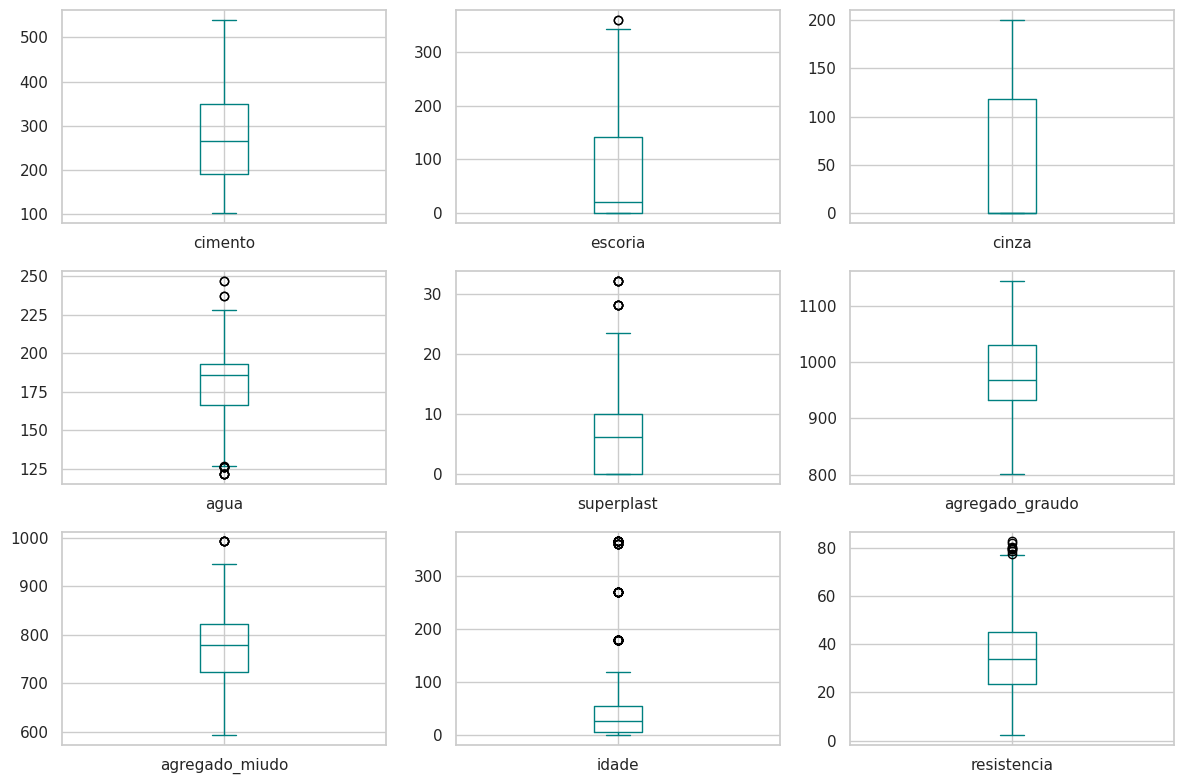

In [ ]:
# Contagem de outliers pelo critério IQR (1.5 x IQR) em todas as colunas
q1 = df.quantile(0.25)
q3 = df.quantile(0.75)
iqr = q3 - q1
outliers = ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum()
print(outliers)

# Boxplot de cada variável (um gráfico por coluna, pois as escalas são diferentes)
df.plot(kind="box", subplots=True, layout=(3, 3), sharey=False, figsize=(12, 8), color="teal")
plt.tight_layout()
plt.show()

### **Análise de Outliers: Diagnóstico e Tratamento**
* **idade**: 59 outliers (valores extremamente altos de tempo de cura, como 365 dias).
* **agua**: 15 outliers.
* **superplast** (superplastificante): 10 outliers.
* **resistencia**: 8 outliers.
* **agregado_miudo**: 5 outliers.
* **escoria**: 2 outliers.

#### **O tratamento atual está correto?**
**Sim, a decisão de não removê-los é tecnicamente correta para este problema pelas seguintes razões:**

1. **Natureza dos Dados (Engenharia Civil):** Valores altos de idade (como cura de 1 ano / 365 dias) ou dosagens extremas de superplastificante e água são perfeitamente possíveis e representam receitas reais de concreto especiais. Não se tratam de erros de digitação ou falhas de medição.
2. **Uso de Regressão Ridge:** A escolha do modelo **Ridge (L2 Regularization)** é excelente para este cenário. A penalização Ridge ajuda a suavizar o impacto de variáveis com alta variância e reduz a sensibilidade do modelo a observações extremas (outliers), mitigando o risco de overfitting sem a necessidade de descartar dados valiosos.

Gerar dataset final copia


In [ ]:
# Gerar dataset final cópia
df_limpo = df.copy()



---



# **Engenharia de Atributos (Feature Engineering) e Análise**

# Criação de novas variáveis

Aplicação do logaritmo à idade (log_idade) para linearizar o ganho de força ao longo do tempo.

In [ ]:
# Aplicação do logaritmo à idade (log_idade)
df["log_idade"] = np.log(df["idade"])

Cálculo da razão água/cimento (agua_cimento) com base na Lei de Abrams.

In [ ]:
# Cálculo da razão água/cimento
df["agua_cimento"] = df["agua"] / df["cimento"]


* **`log_idade` (Logaritmo da Idade):** O concreto ganha muita resistência nos primeiros dias e quase estabiliza depois. Modelos lineares não entendem esse comportamento curvado. Aplicar o logaritmo transforma essa curva exponencial em uma linha reta, facilitando o aprendizado do modelo.

* **`agua_cimento` (Razão Água/Cimento):** Pela física da construção (Lei de Abrams), esta proporção é o fator que mais dita a força do concreto (mais água enfraquece, mais cimento fortalece). Como modelos lineares não conseguem dividir uma coluna pela outra sozinhos, nós já entregamos esse cálculo pronto para ele.

# Análise de correlação

Estudo da Correlação de Pearson para identificar quais as variáveis que mais se correlacionam positivamente (ex: log_idade, cimento) ou negativamente (ex: agua_cimento, agua) com a resistência.

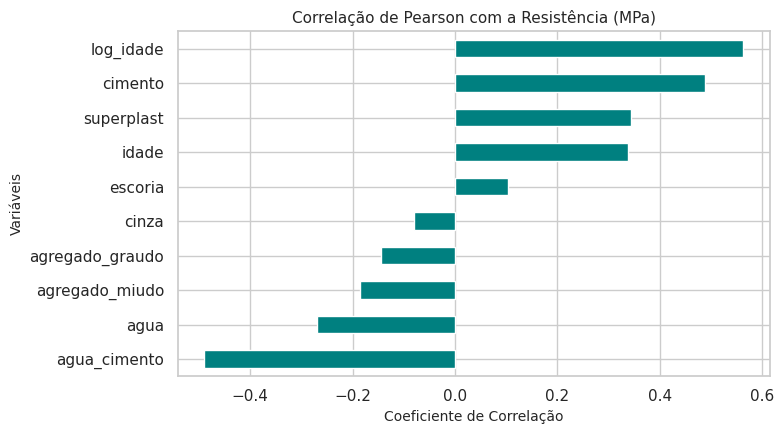

In [ ]:
# Estudo da Correlação de Pearson com a Resistência
plt.figure(figsize=(8, 4.5))
corr = df.corr()["resistencia"].drop("resistencia").sort_values()
corr.plot(kind="barh", color="teal")
plt.title("Correlação de Pearson com a Resistência (MPa)", fontsize=11)
plt.xlabel("Coeficiente de Correlação", fontsize=10)
plt.ylabel("Variáveis", fontsize=10)
plt.tight_layout()
plt.show()


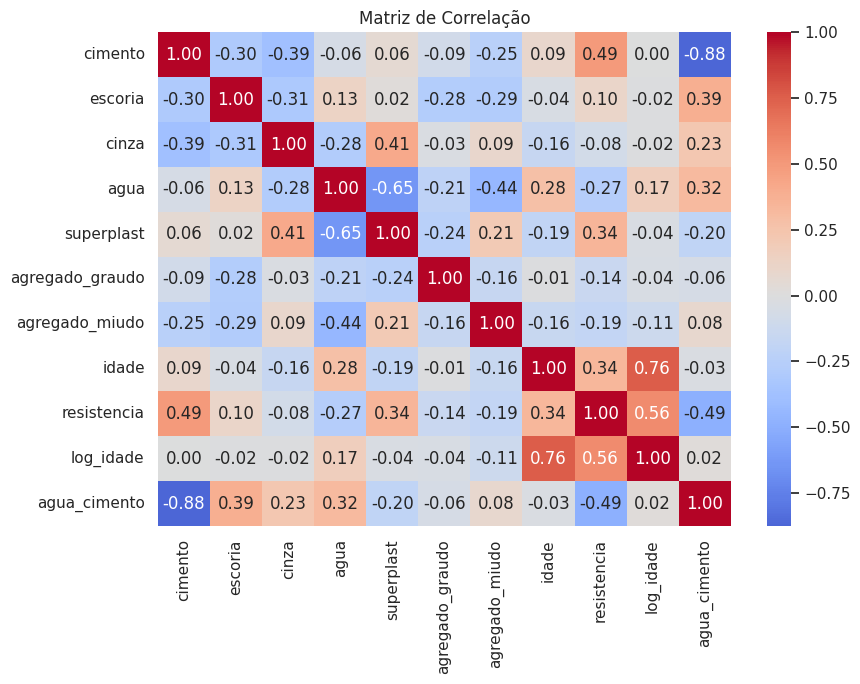

In [ ]:
# Correlação entre as variáveis (multicolinearidade)
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de Correlação")
plt.tight_layout()
plt.show()

Relações principais: **Cimento, razão água/cimento e log da idade contra a resistência.** O heatmap mostra também a correlação entre as variáveis de entrada: `agua`, `cimento` e `agua_cimento` são relacionadas entre si (multicolinearidade), o que justifica a penalização L2 do Ridge.

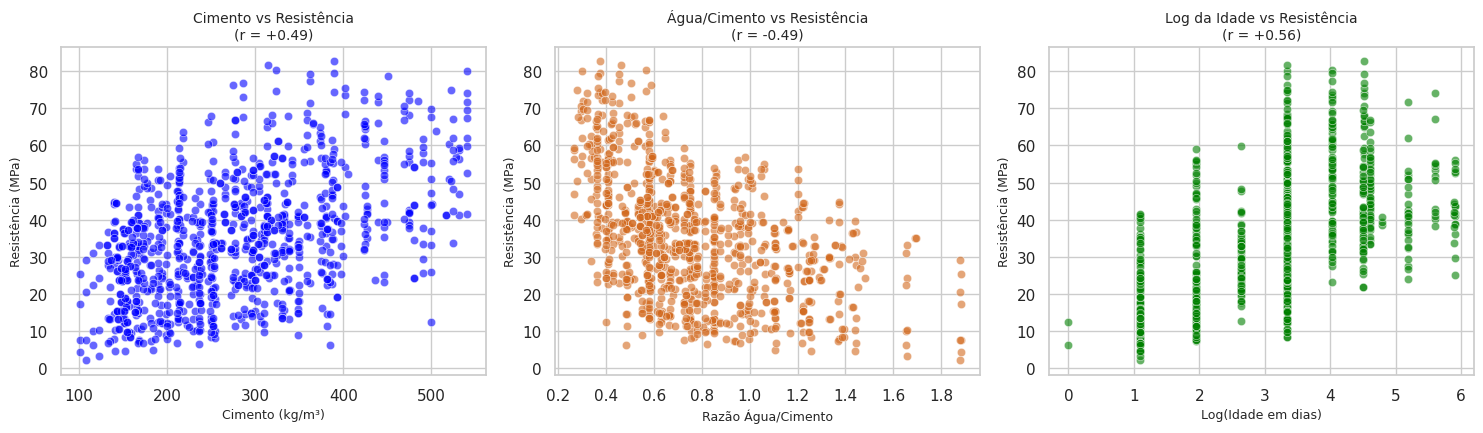

In [ ]:
# Relações principais (o valor de r é calculado a partir da correlação)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.scatterplot(data=df, x="cimento", y="resistencia", alpha=0.6, ax=axes[0], color="blue")
axes[0].set_title(f"Cimento vs Resistência\n(r = {corr['cimento']:+.2f})", fontsize=10)
axes[0].set_xlabel("Cimento (kg/m³)", fontsize=9)
axes[0].set_ylabel("Resistência (MPa)", fontsize=9)

sns.scatterplot(data=df, x="agua_cimento", y="resistencia", alpha=0.6, ax=axes[1], color="chocolate")
axes[1].set_title(f"Água/Cimento vs Resistência\n(r = {corr['agua_cimento']:+.2f})", fontsize=10)
axes[1].set_xlabel("Razão Água/Cimento", fontsize=9)
axes[1].set_ylabel("Resistência (MPa)", fontsize=9)

sns.scatterplot(data=df, x="log_idade", y="resistencia", alpha=0.6, ax=axes[2], color="green")
axes[2].set_title(f"Log da Idade vs Resistência\n(r = {corr['log_idade']:+.2f})", fontsize=10)
axes[2].set_xlabel("Log(Idade em dias)", fontsize=9)
axes[2].set_ylabel("Resistência (MPa)", fontsize=9)

plt.tight_layout()
plt.show()



---



## **Modelagem (Preparação e Treino)**

Sepuração de variáveis: **Definição das variáveis preditoras de entrada ($X$, excluindo a resistência e a idade bruta) e da variável alvo ($y$, correspondente à resistencia em MPa).**   

In [ ]:
# Definição das variáveis preditoras de entrada X e da variável alvo y
X = df.drop(columns=["resistencia", "idade"])
y = df["resistencia"]

Divisão dos dados: **Divisão do conjunto em dados de treino (80%) e dados de teste (20%) utilizando a função train_test_split**

In [ ]:
# Divisão do conjunto em dados de treino (80%) e dados de teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Criação do Pipeline: **Configuração de um fluxo que inclui a normalização de escala com StandardScaler (média 0 e desvio padrão 1) e o modelo de Regressão Ridge com penalização L2 (Ridge(alpha=1.0)) para controlar o overfitting.**

In [ ]:
# Configuração do Pipeline com StandardScaler e Ridge Regression
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0))
])

Treinamento do modelo: **Ajuste do modelo utilizando exclusivamente os dados de treino.**

In [ ]:
# Validação Cruzada (5 folds) e Treinamento do modelo nos dados de treino
scores_cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring='r2')
print(f"Scores R² na Validação Cruzada (5 folds): {scores_cv}")
print(f"Média do R² na Validação Cruzada: {scores_cv.mean():.2f} (+/- {scores_cv.std() * 2:.2f})")

# Treinamento final
pipe.fit(X_train, y_train)

Scores R² na Validação Cruzada (5 folds): [0.78799459 0.81269712 0.82759572 0.82546389 0.79429831]
Média do R² na Validação Cruzada: 0.81 (+/- 0.03)


Pipeline(steps=[('scaler', StandardScaler()), ('ridge', Ridge())])

Ajuste do hiperparâmetro: **busca do melhor `alpha` do Ridge por validação cruzada (5 folds), usando apenas os dados de treino. O modelo final é o pipeline com o melhor alpha.**

In [ ]:
# Busca do melhor alpha com validação cruzada (somente dados de treino)
parametros = {"ridge__alpha": [0.01, 0.1, 1, 10, 100]}
busca = GridSearchCV(pipe, parametros, cv=5, scoring="r2")
busca.fit(X_train, y_train)
print(f"Melhor alpha: {busca.best_params_['ridge__alpha']} | R² na validação cruzada: {busca.best_score_:.2f}")

# Modelo final: melhor pipeline, já treinado nos dados de treino
pipe = busca.best_estimator_

Melhor alpha: 1 | R² na validação cruzada: 0.81




---



## **Avaliação do Modelo**

Previsão no conjunto de teste: **Aplicação do modelo treinado (pipe.predict) aos dados guardados para teste.**

In [ ]:
# Previsão no conjunto de teste
y_pred = pipe.predict(X_test)

# Métricas de desempenho

Cálculo do coeficiente de determinação ($R^2$) para medir a variância explicada.

In [ ]:
# Cálculo do R²
r2 = r2_score(y_test, y_pred)
print(f"R² no conjunto de teste: {r2:.2f}")

R² no conjunto de teste: 0.81


Cálculo da raiz do erro quadrático médio (RMSE) para aferir o erro típico na mesma unidade do alvo (MPa).

In [ ]:
# Cálculo do RMSE
rmse = mean_squared_error(y_test, y_pred) ** 0.5
print(f"RMSE no conjunto de teste: {rmse:.2f} MPa")

RMSE no conjunto de teste: 7.59 MPa


Cálculo do erro absoluto médio (MAE), que mostra o erro médio em MPa sem dar peso extra aos erros grandes.

In [ ]:
# Cálculo do MAE
mae = mean_absolute_error(y_test, y_pred)
print(f"MAE no conjunto de teste: {mae:.2f} MPa")

MAE no conjunto de teste: 5.79 MPa


Análise do resíduo médio para confirmar que os erros estão centrados perto de zero.

Resíduo médio: +1.17 MPa


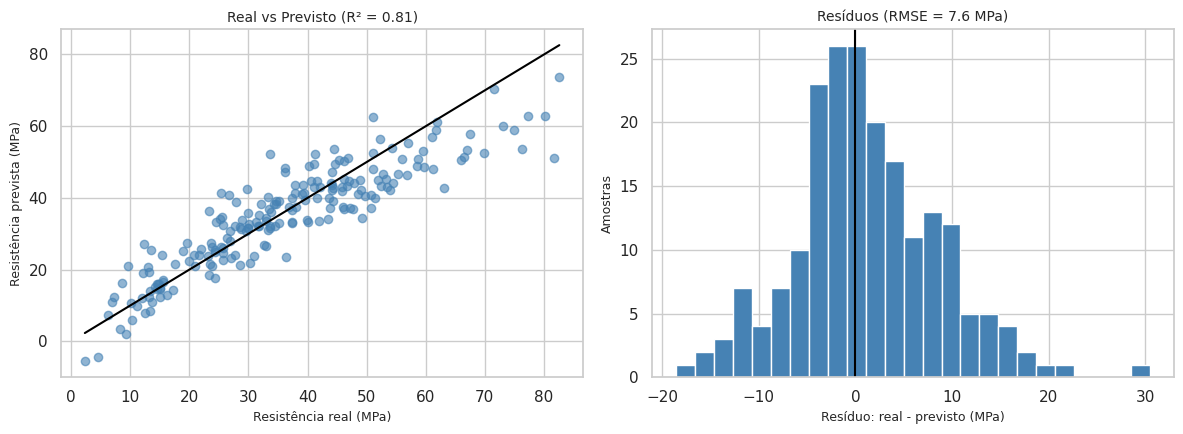

In [ ]:
# Resíduos = valor real - valor previsto
residuos = y_test - y_pred
print(f"Resíduo médio: {residuos.mean():+.2f} MPa")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Real vs Previsto (quanto mais perto da linha, melhor)
axes[0].scatter(y_test, y_pred, alpha=0.6, color="steelblue")
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], color="black")
axes[0].set_title(f"Real vs Previsto (R² = {r2:.2f})", fontsize=10)
axes[0].set_xlabel("Resistência real (MPa)", fontsize=9)
axes[0].set_ylabel("Resistência prevista (MPa)", fontsize=9)

# Distribuição dos resíduos (deve estar centrada perto de zero)
axes[1].hist(residuos, bins=25, color="steelblue", edgecolor="white")
axes[1].axvline(0, color="black")
axes[1].set_title(f"Resíduos (RMSE = {rmse:.1f} MPa)", fontsize=10)
axes[1].set_xlabel("Resíduo: real - previsto (MPa)", fontsize=9)
axes[1].set_ylabel("Amostras", fontsize=9)

plt.tight_layout()
plt.show()

Diagnóstico de overfitting e underfitting: **comparação do R² de treino e de teste do Ridge com um baseline (média), a Regressão Linear e um modelo não linear (Gradient Boosting).** Treino muito acima do teste indica overfitting; treino e teste baixos indicam underfitting.

In [ ]:
# Comparação de modelos: R² no treino vs R² no teste
modelos = {
    "Baseline (média)": DummyRegressor(),
    "Regressão Linear": LinearRegression(),
    "Ridge (final)": Ridge(alpha=pipe.named_steps["ridge"].alpha),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

resultados = []
for nome, modelo in modelos.items():
    m = Pipeline([("scaler", StandardScaler()), ("modelo", modelo)])
    m.fit(X_train, y_train)
    r2_treino = r2_score(y_train, m.predict(X_train))
    r2_teste = r2_score(y_test, m.predict(X_test))
    rmse_teste = mean_squared_error(y_test, m.predict(X_test)) ** 0.5
    resultados.append([nome, r2_treino, r2_teste, r2_treino - r2_teste, rmse_teste])

display(pd.DataFrame(resultados, columns=["Modelo", "R² treino", "R² teste", "Diferença", "RMSE teste (MPa)"]).round(2))

,Modelo,R² treino,R² teste,Diferença,RMSE teste (MPa)
0,Baseline (média),0.00,-0.00,0.00,17.30
1,Regressão Linear,0.82,0.81,0.01,7.59
2,Ridge (final),0.82,0.81,0.01,7.59
3,Gradient Boosting,0.95,0.91,0.04,5.29


Leitura: o Ridge tem R² de treino e de teste praticamente iguais, então **não há overfitting**. Porém o ganho do Gradient Boosting mostra que a relação tem partes não lineares que o modelo linear não captura (**underfitting leve**). O Ridge segue como modelo final por ser simples, interpretável e fácil de levar ao deploy; modelos não lineares ficam como próximo passo.



---



# **Deploy**

Guardar o modelo treinado: **Exportação do pipeline completo e treinado para um ficheiro externo (modelo_concreto.joblib) utilizando a biblioteca joblib.**

In [ ]:
# Exportação do pipeline de modelo treinado para ficheiro externo
joblib.dump(pipe, 'modelo_concreto.joblib')
print("Modelo guardado com sucesso como 'modelo_concreto.joblib'!")

Modelo guardado com sucesso como 'modelo_concreto.joblib'!


## **Desenvolvimento da Interface: Dashboard usando o STREAMLIT**

---

# **Conclusão**

**Impacto**
- Decisão mais rápida, sem esperar os 28 dias de cura.
- Menos desperdício de cimento e de tempo de laboratório.
- Conformidade estrutural verificada antes da obra.

**Limitações e próximos passos**
- O dataset não tem temperatura nem umidade de cura.
- O modelo linear (Ridge) subestima relações não lineares; testar modelos como Gradient Boosting ou Random Forest.
- O app deve ser usado dentro das faixas de dosagem do dataset original (previsões fora dessas faixas não são confiáveis).